### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DMFM = data.copy()
DMFM = DMFM[DMFM['category']=='miscellaneous food']
DMFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
80,1/15/2008,Shan (South),Taunggyi,Taunggyi,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,121.21,0.0681
85,2/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
160,2/15/2008,Shan (South),Taunggyi,Taunggyi,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,121.21,0.0681
239,3/15/2008,Shan (South),Taunggyi,Taunggyi,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,121.21,0.0681


In [13]:
DMFM = DMFM[['date', 'price']]
DMFM['date'] = pd.to_datetime(DMFM['date'])
mask = (DMFM['date']>=obv_st_date) & (DMFM['date']<=obv_end_date)
DMFM = DMFM.loc[mask]
DMFM = DMFM.set_index('date')
DMFM.head()

,price
date,
2008-01-15,242.42
2008-01-15,121.21
2008-02-15,242.42
2008-02-15,121.21
2008-03-15,121.21


In [14]:
DMFM = DMFM.resample('MS').mean()
DMFM.head()

,price
date,
2008-01-01,181.815
2008-02-01,181.815
2008-03-01,121.210
2008-04-01,439.395
2008-05-01,484.850


In [15]:
DMFM.shape

(169, 1)

In [16]:
price = DMFM['price']
date = DMFM.index

##### Normalization data5

In [17]:
scaler = MinMaxScaler()

In [18]:
DMFM = scaler.fit_transform(DMFM)
DMFM = pd.DataFrame(DMFM)
DMFM.head()

,0
0,0.097945
1,0.097945
2,0.000000
3,0.514227
4,0.587688


In [19]:
DMFM['date']=date
DMFM = DMFM.set_index('date')
DMFM.columns=['price']
DMFM.head()

,price
date,
2008-01-01,0.097945
2008-02-01,0.097945
2008-03-01,0.000000
2008-04-01,0.514227
2008-05-01,0.587688


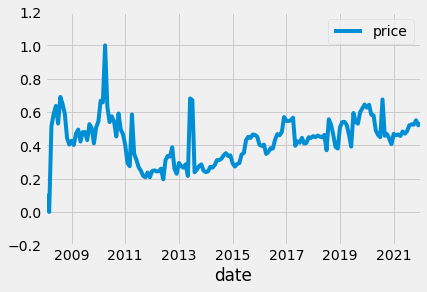

In [20]:
DMFM.plot(grid=True)
plt.show()

It has no trend

##### Checking Random Walk

In [21]:
RW_DMFM= adfuller(DMFM)
RW_DMFM[1] # print P-value. If p-value<5%, reject null hypothesis

0.00021811006118204753

##### Plotting ACF and PACF

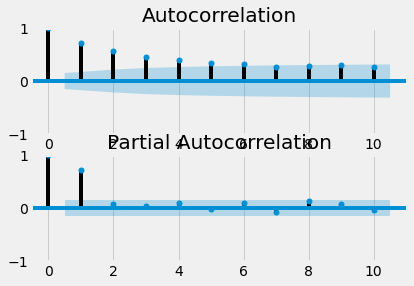

In [22]:
fig, axes=plt.subplots(2,1)
plot_acf(DMFM, lags=10, ax=axes[0])
plot_pacf(DMFM, lags=10, ax=axes[1])
plt.show()

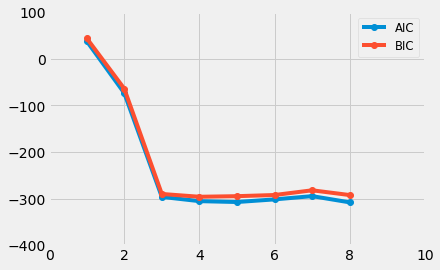

In [23]:
AIC, BIC = AIC_BIC_withOrderRange(DMFM, p=3, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [24]:
AIC, BIC

(array([ 211.56329257,   37.75239585,  -73.59158182, -296.24139742,
        -305.36197484, -307.22431076, -301.59349959, -294.64434379,
        -307.95853022]),
 array([ 214.69319128,   44.01219328,  -64.20188568, -289.98159999,
        -295.9722787 , -294.7047159 , -292.20380344, -282.12474893,
        -292.30903665]))

We will run again 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [25]:
mod_orders = [
    (1,0,0),
    (1,0,1),
    (1,0,2),
    (2,0,0),
    (2,0,1),
    (2,0,2)
]

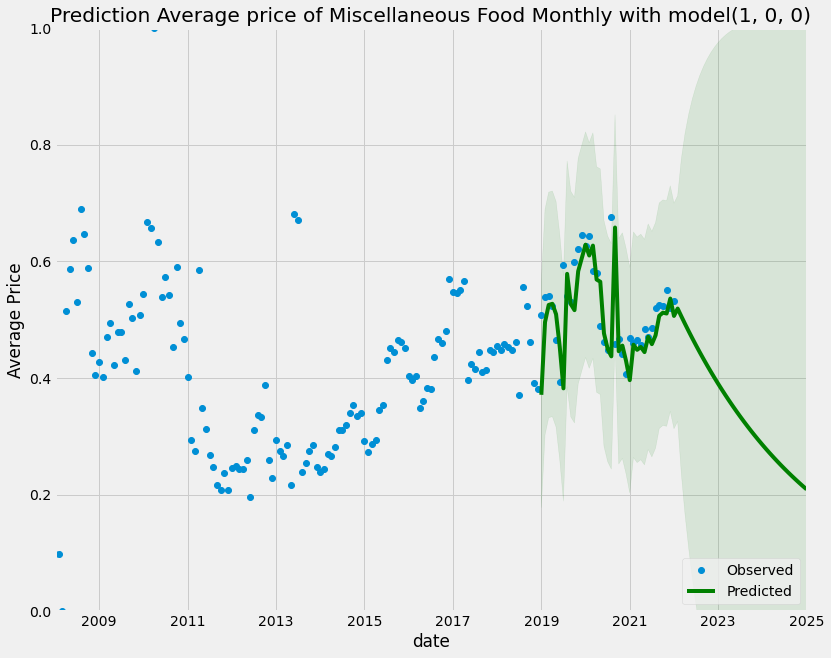

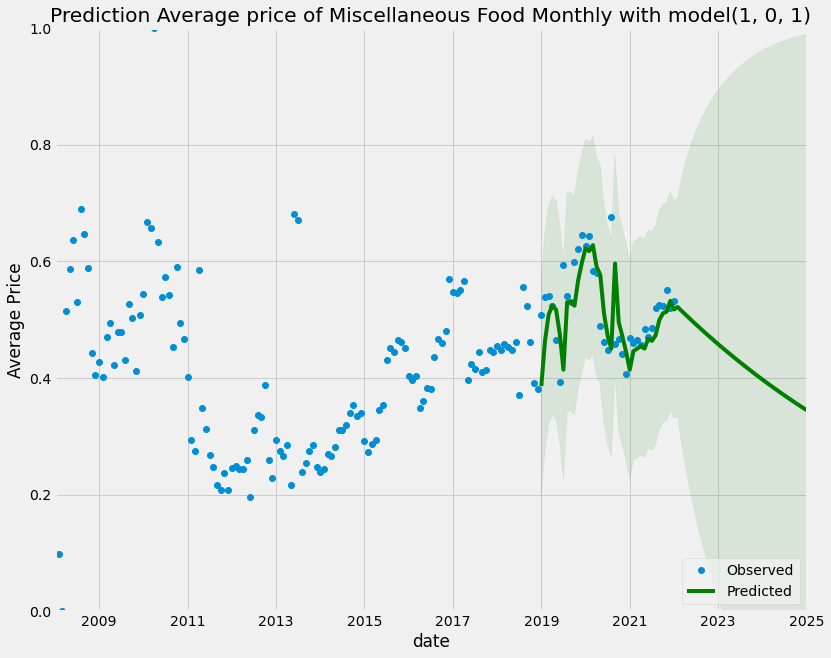

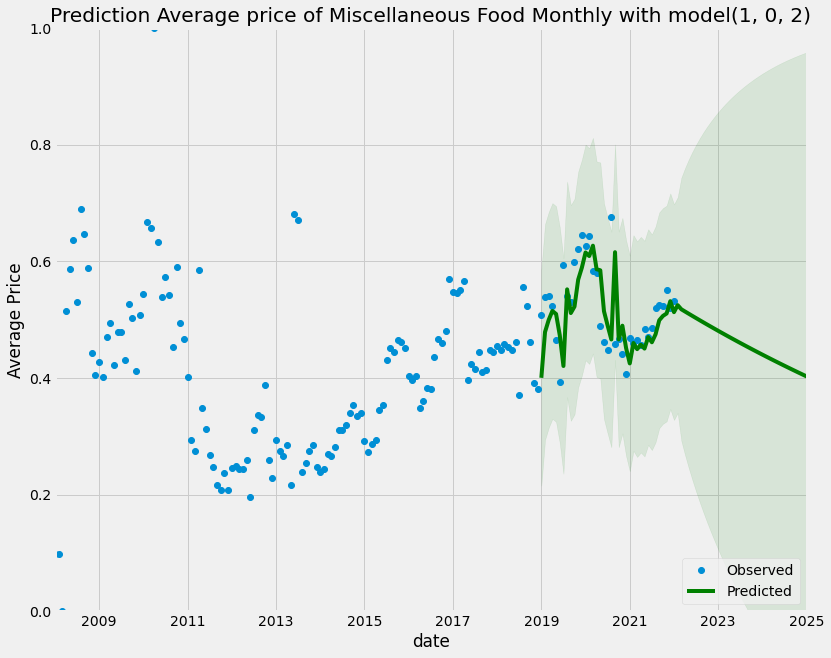

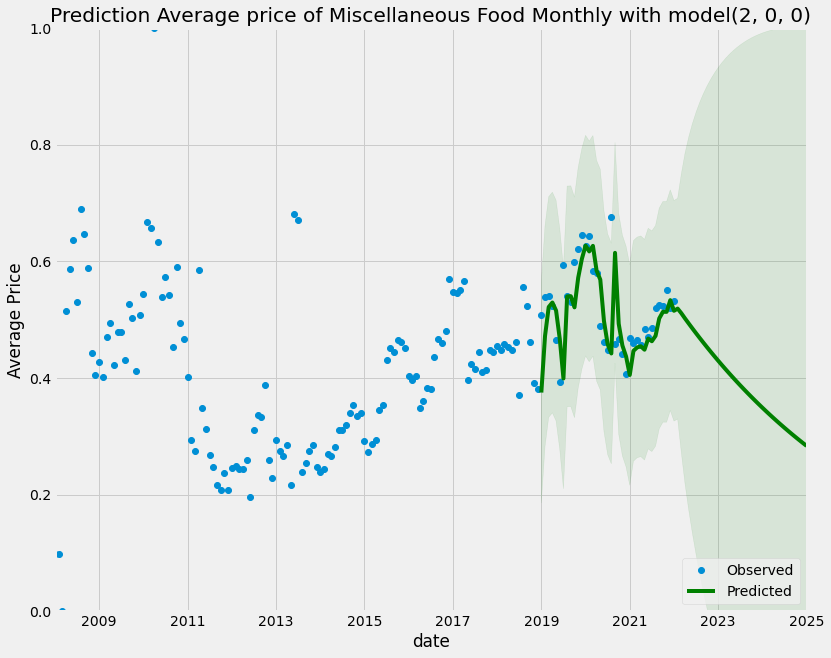

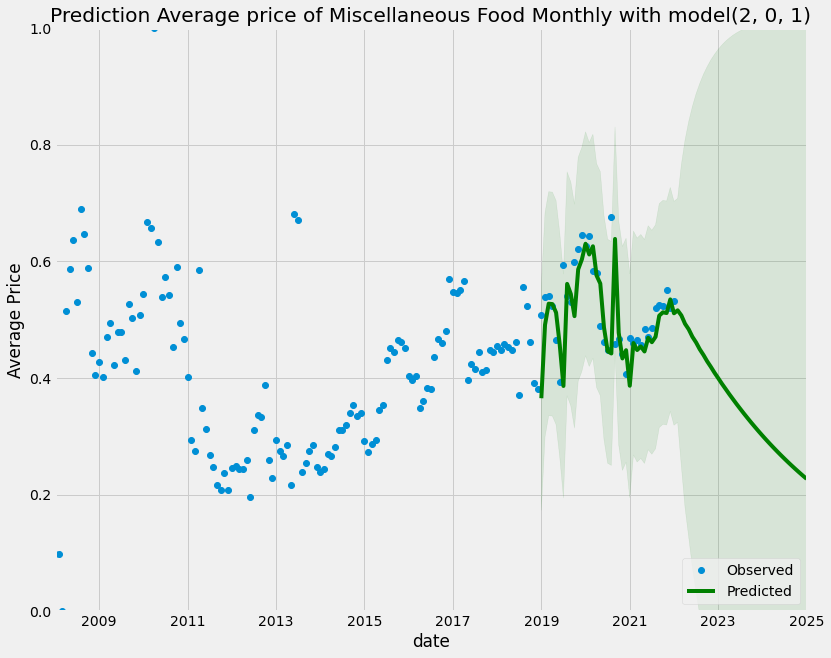

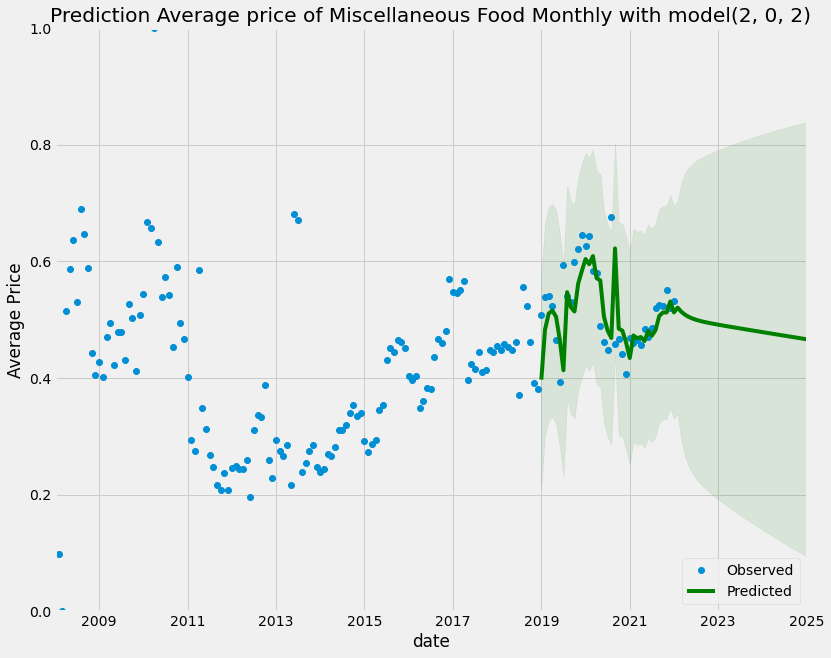

In [26]:
DMFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Miscellaneous Food Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFM_models.append(model)

Now we choose (1,0,2)

In [27]:
DMFM_model = DMFM_models[2]

In [28]:
DMFM_pred_normalized = DMFM_model.predict(pred_st_date, pred_end_date)
DMFM_pred_normalized

2019-01-01    0.400357
2019-02-01    0.478841
2019-03-01    0.499608
2019-04-01    0.515018
2019-05-01    0.509781
                ...   
2024-09-01    0.414807
2024-10-01    0.411751
2024-11-01    0.408717
2024-12-01    0.405706
2025-01-01    0.402717
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64

We need to un-normalized the predicted value to get actual price

In [29]:
pred_date = DMFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

In [30]:
DMFM_pred_normalized_df = pd.DataFrame(DMFM_pred_normalized)
DMFM_pred_normalized_df = DMFM_pred_normalized_df[:-1] # the last index doesn't need
DMFM_pred_normalized_df

,predicted_mean
2019-01-01,0.400357
2019-02-01,0.478841
2019-03-01,0.499608
2019-04-01,0.515018
2019-05-01,0.509781
...,...
2024-08-01,0.417886
2024-09-01,0.414807
2024-10-01,0.411751
2024-11-01,0.408717


##### Un-normalization data

In [31]:
DMFM_pred_act = scaler.inverse_transform(DMFM_pred_normalized_df)
DMFM_pred_act_df = pd.DataFrame(DMFM_pred_act)
DMFM_pred_act_df['date'] = pred_date
DMFM_pred_act_df.columns = ['Predicted Price', 'date']
DMFM_pred_act_df.set_index('date',  inplace=True)
DMFM_pred_act_df

,Predicted Price
date,
2019-01-01,368.936420
2019-02-01,417.499305
2019-03-01,430.349398
2019-04-01,439.884459
2019-05-01,436.643941
...,...
2024-08-01,379.782704
2024-09-01,377.877593
2024-10-01,375.986518
